In [82]:
import numpy as np
import matplotlib.pyplot as plt
import allantools
import struct


In [83]:
PATH = "../spectrometer/"
# fname = "20261016-223203_vlf.bin"

# fname = "20261016-235909_vlf.bin" #With USBC power decoy
# fname = "20261017-000127_vlf.bin" #With 12V battery
# fname = "20261017-000356_vlf.bin" #With battery

# fname = "20261017-200125_vlf.bin" #With battery, 2 hour run

# fname = "20261021-082604_vlf.bin"

# fname = "20261021-090741_vlf.bin"
# fname = "20261021-091032_vlf.bin"
# fname = "20261022-194847_vlf.bin"
fname = "20261022-195139_vlf.bin"

metadata = np.fromfile(PATH+fname, dtype=np.float64, count=128)
epoch = metadata[0]
fs = int(metadata[1])
NFFT = int(metadata[2])
actual_t_int = metadata[3]
datafmt = int(metadata[4])

obs_ident_encoded = metadata[5]
raw_bytes = struct.pack('<d', obs_ident_encoded)
clean_bytes = raw_bytes.split(b'\x00')[0]
obs_ident = clean_bytes.decode('ascii')

print (f"epoch = {epoch}, \nfs = {fs}, \nNFFT = {NFFT}, \nactual_t_int = {actual_t_int}, \ndatafmt = {datafmt}, \nobs_ident = {obs_ident}")

len_spectrum = int(NFFT/2)+1+1
if datafmt==0:
    rawdata = np.memmap(PATH+fname, dtype=np.float64, offset=1024, mode='r')
else:
    rawdata = np.memmap(PATH+fname, dtype=np.float32, offset=1024, mode='r')

N_good_spectra = int(len(rawdata)/len_spectrum) #The idea here is to avoid the last corrupted spectrum, if any, due to a sudden exit in the acq code
data_w_timestamps = np.reshape(rawdata[0:int(N_good_spectra*len_spectrum)], (N_good_spectra, len_spectrum))
timestamps = epoch+np.asarray(data_w_timestamps[:,0], dtype=np.float64)
spectra = data_w_timestamps[:,1:]

epoch = 1792698699.8786678, 
fs = 48000, 
NFFT = 32768, 
actual_t_int = 0.6826666593551636, 
datafmt = 1, 
obs_ident = TEST


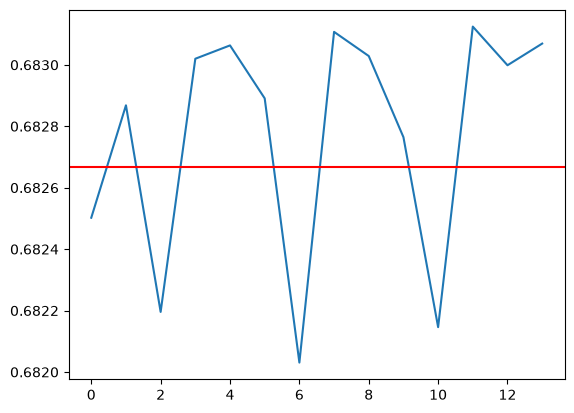

In [84]:
plt.figure()
plt.plot(np.diff(timestamps))
plt.axhline(actual_t_int, color='red')

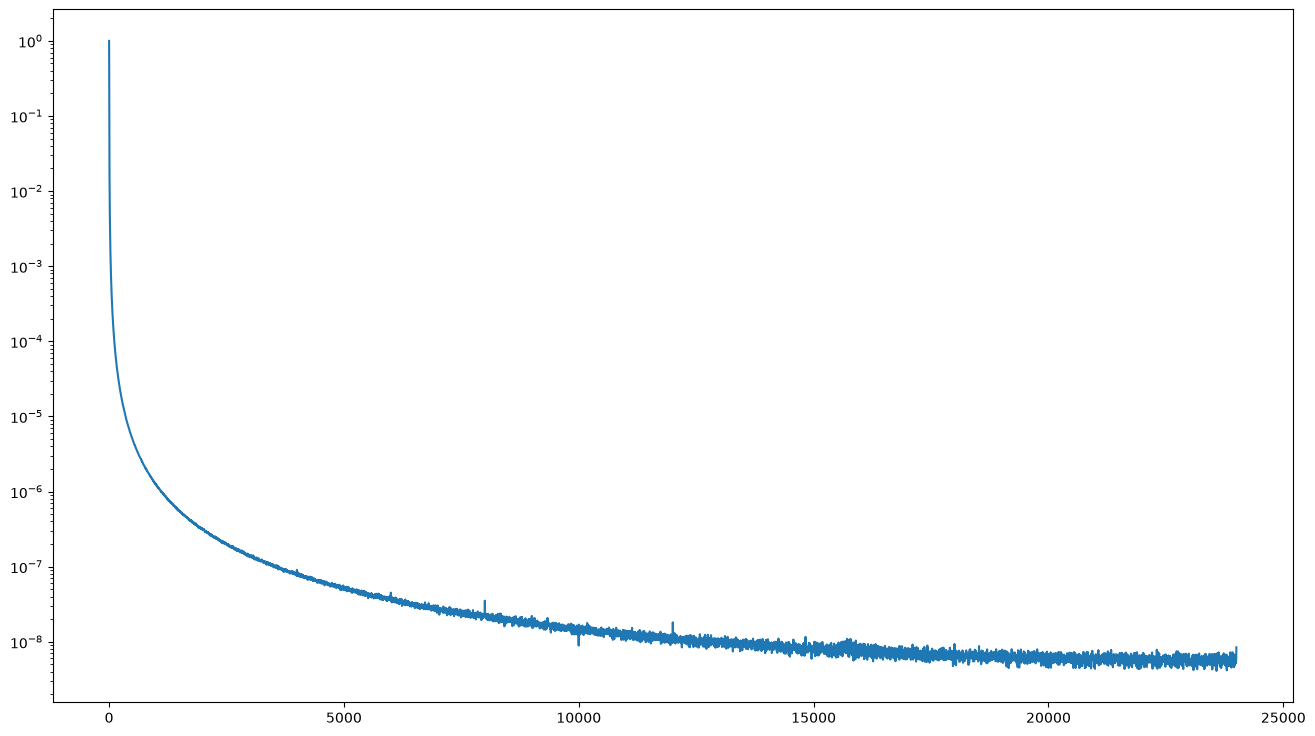

In [85]:
freq = np.linspace(0, fs/2, len_spectrum-1)
mean_spec = np.mean(spectra[:,:], axis=0)

plt.figure(figsize=(16,9))
plt.semilogy(freq, mean_spec/np.max(mean_spec)) #
# plt.ylim(1e-5, 1e-4)
# plt.xlim(0, 5e3)

In [86]:
spectra.shape

(15, 16385)

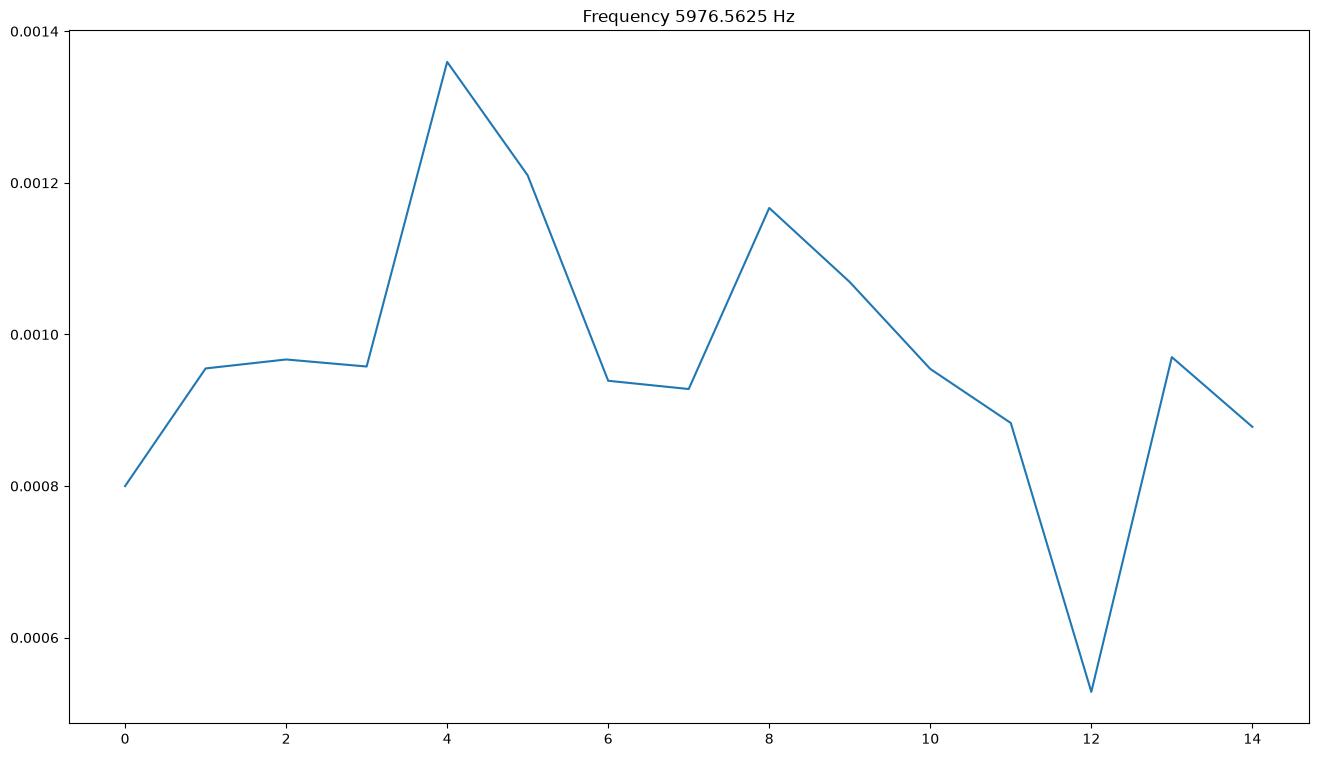

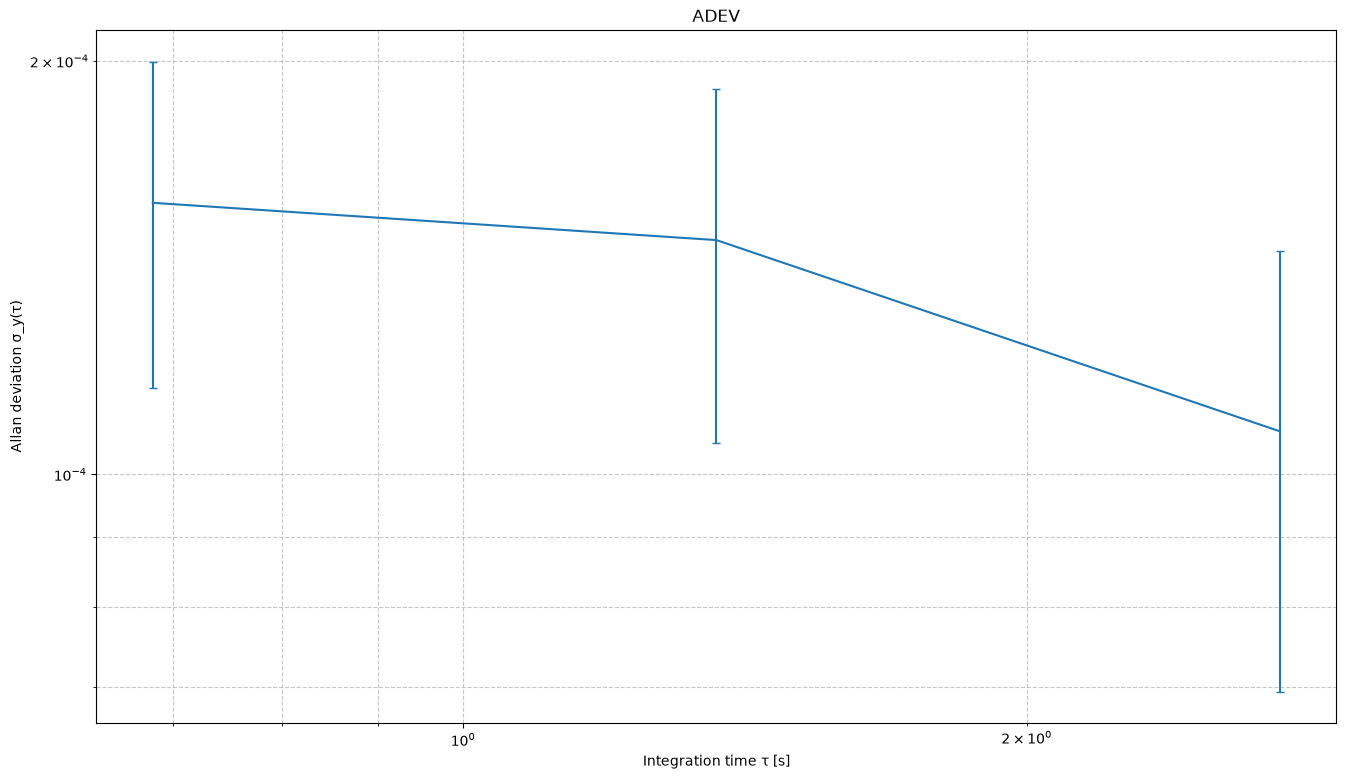

In [87]:
chan_index = 4080
y = spectra[:, chan_index] #Some random channel

plt.figure(figsize=(16,9))
plt.title(f"Frequency {freq[chan_index]} Hz")
plt.plot(y) #

tau, adev, adev_err, n = allantools.oadev(y, rate=1/actual_t_int, data_type='freq') # rate needs a second look
plt.figure(figsize=(16,9))
plt.title(f'ADEV')
plt.errorbar(tau, adev, yerr=adev_err, fmt='-', capsize=3)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Integration time τ [s]')
plt.ylabel('Allan deviation σ_y(τ)')
plt.grid(which='both', linestyle='--', alpha=0.7)

In [88]:
# zoom_indices = np.where((freq>100) & (freq<48e3))[0]

# pfit_c = np.polyfit(np.linspace(-1,1,len(freq[zoom_indices])), np.log10(mean_spec[zoom_indices]), 30)
# pval = 10**(np.polyval(pfit_c, np.linspace(-1,1,len(freq[zoom_indices]))))

# plt.figure(figsize=(16,9))
# plt.semilogy(freq[zoom_indices], mean_spec[zoom_indices]/pval) #/np.max(mean_spec)
# # plt.semilogy(freq, pval)
# # plt.ylim(1e-5, 1e-4)
# # plt.xlim(0, 5e3)

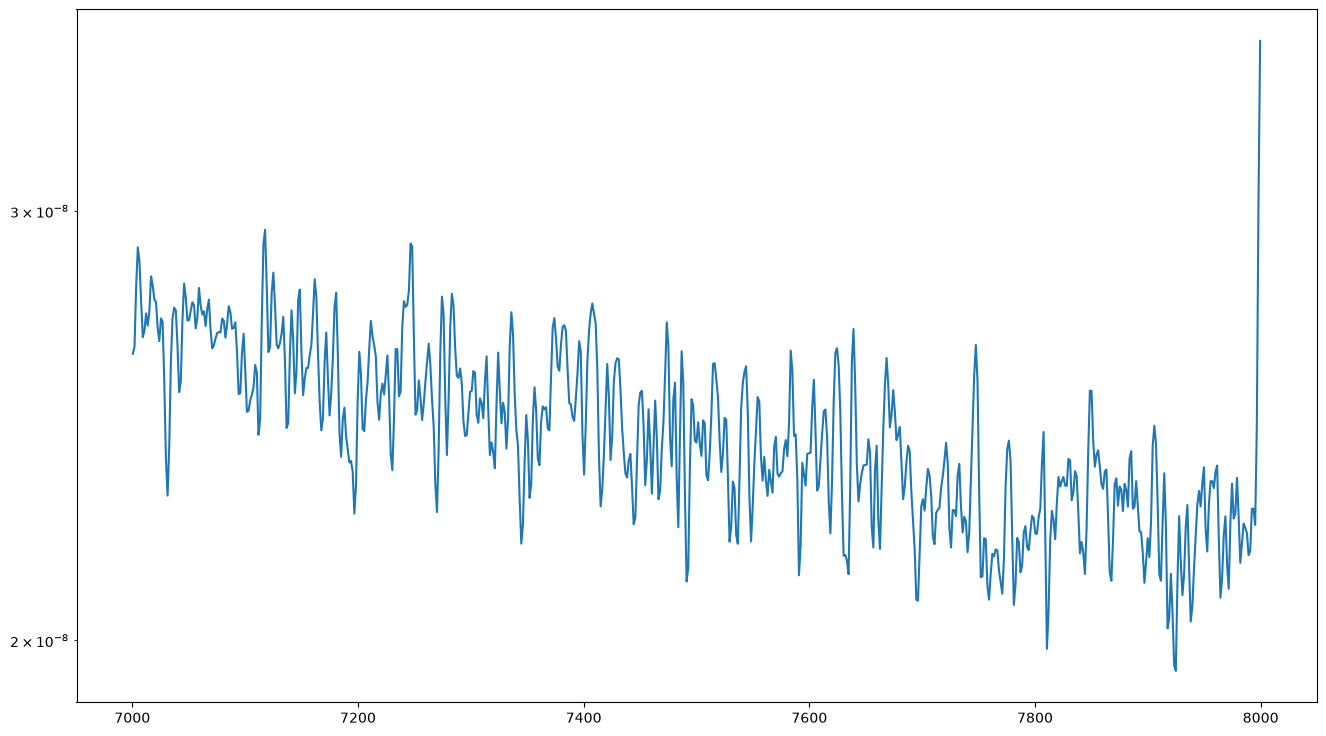

In [89]:
zoom_indices = np.where((freq>7e3) & (freq<8e3))[0]

plt.figure(figsize=(16,9))
plt.semilogy(freq[zoom_indices],(mean_spec/np.max(mean_spec))[zoom_indices])

In [90]:
# plt.figure(figsize=(16,9))
# plt.imshow(np.log(spectra), cmap='plasma', aspect='auto')
